In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df=pd.read_csv("ecommerce_dataset.csv")

In [3]:
df.dtypes

Order_ID           int64
Order_Date        object
City              object
Category          object
Product           object
Quantity           int64
Unit_Price         int64
Discount           int64
Sales            float64
Cost             float64
Profit           float64
Payment_Mode      object
Rating             int64
Delivery_Days      int64
dtype: object

In [4]:
df.isnull().sum()

Order_ID         0
Order_Date       0
City             0
Category         0
Product          0
Quantity         0
Unit_Price       0
Discount         0
Sales            0
Cost             0
Profit           0
Payment_Mode     0
Rating           0
Delivery_Days    0
dtype: int64

In [5]:
df.duplicated().sum()

0

In [6]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [7]:
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%B')
df['Year_Month'] = df['Order_Date'].dt.to_period('M')

In [8]:
df.head()

,Order_ID,Order_Date,City,Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Mode,Rating,Delivery_Days,Year,Month,Month_Name,Year_Month
0,1001,2025-01-01,Chennai,Furniture,Sofa,4,17396,0,69584.00,46310.58,23273.42,Card,5,5,2025,1,January,2025-01
1,1002,2025-01-02,Pune,Grocery,Snacks,3,46675,0,140025.00,92774.12,47250.88,Cash,5,5,2025,1,January,2025-01
2,1003,2025-01-03,Hyderabad,Electronics,Headphones,1,8305,25,6228.75,3627.01,2601.74,Net Banking,5,4,2025,1,January,2025-01
3,1004,2025-01-04,Hyderabad,Furniture,Chair,4,5737,0,22948.00,16485.86,6462.14,Net Banking,4,6,2025,1,January,2025-01
4,1005,2025-01-05,Bengaluru,Furniture,Bed,6,20556,20,98668.80,78019.85,20648.95,UPI,5,3,2025,1,January,2025-01


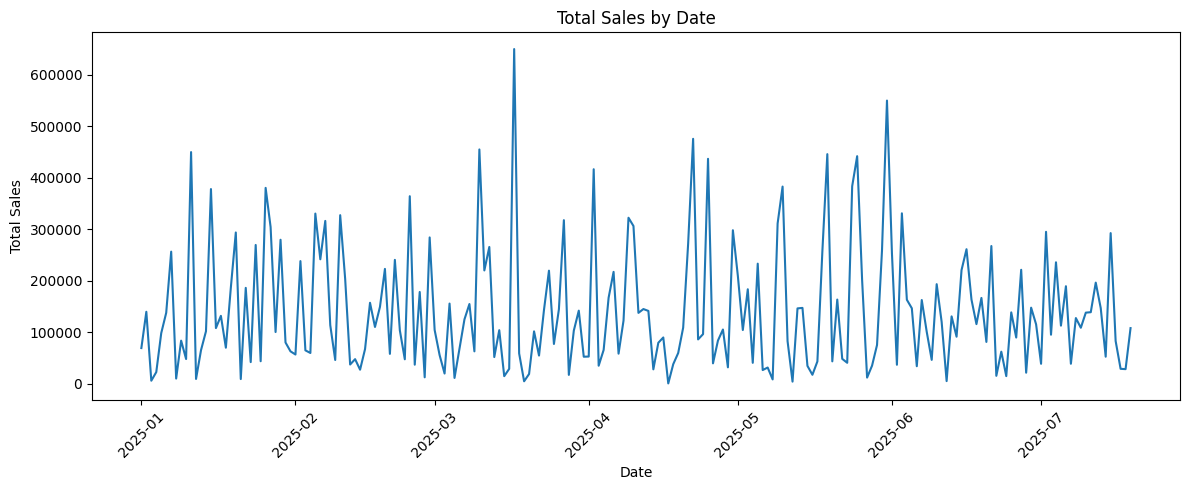

In [9]:
daily_sales = df.groupby('Order_Date')['Sales'].sum()

plt.figure(figsize=(12, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Total Sales by Date')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

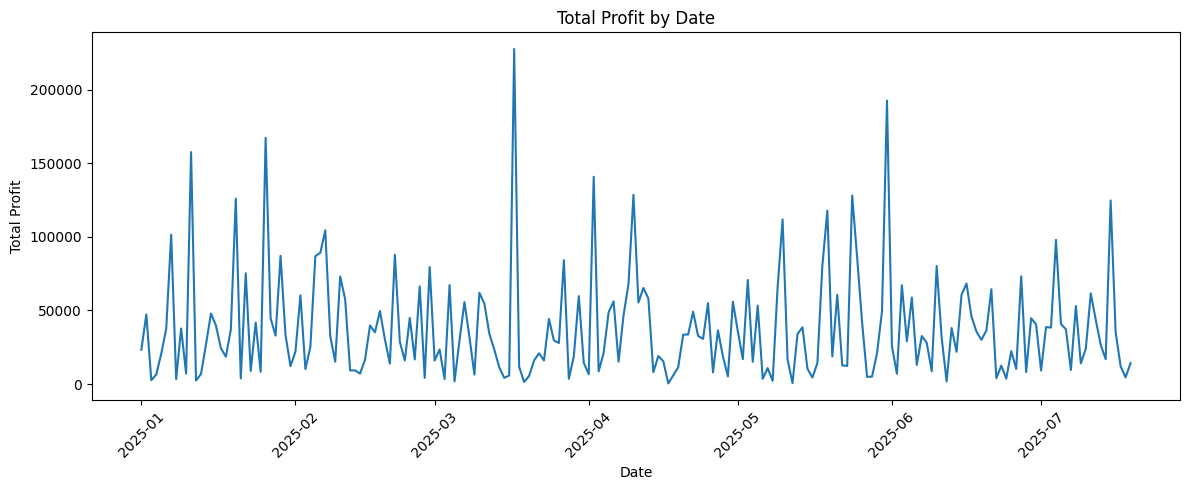

In [10]:
#total proft by date
daily_profit = df.groupby('Order_Date')['Profit'].sum()

plt.figure(figsize=(12, 5))

plt.plot(daily_profit.index, daily_profit.values)

plt.xlabel('Date')
plt.ylabel('Total Profit')
plt.title('Total Profit by Date')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

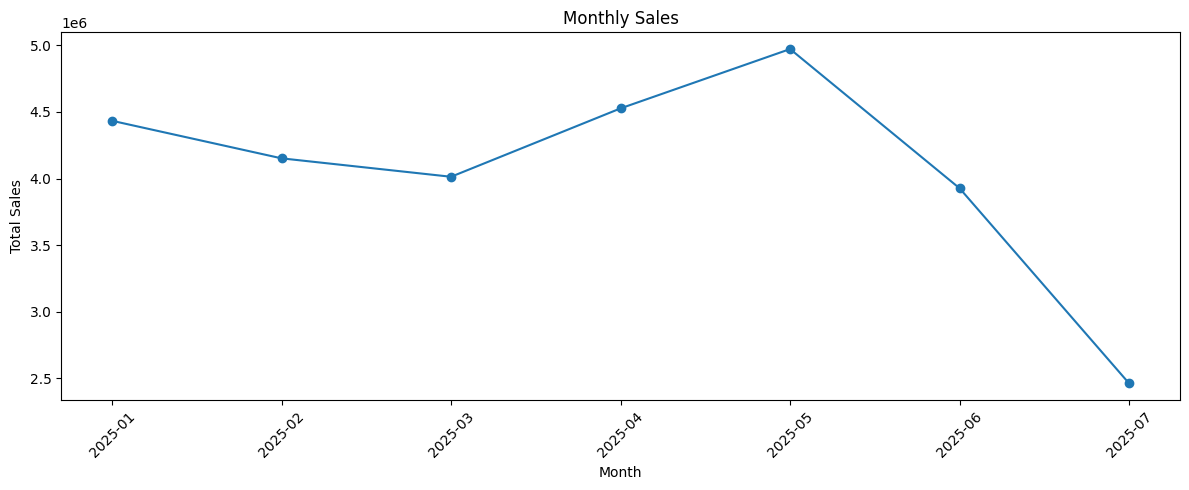

In [11]:
#monly sales -highest sale
monthly_sales = df.groupby('Year_Month')['Sales'].sum()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

print("Highest Sales Month:", highest_month)
print("Sales:", highest_sales)

Highest Sales Month: 2025-05
Sales: 4972117.25


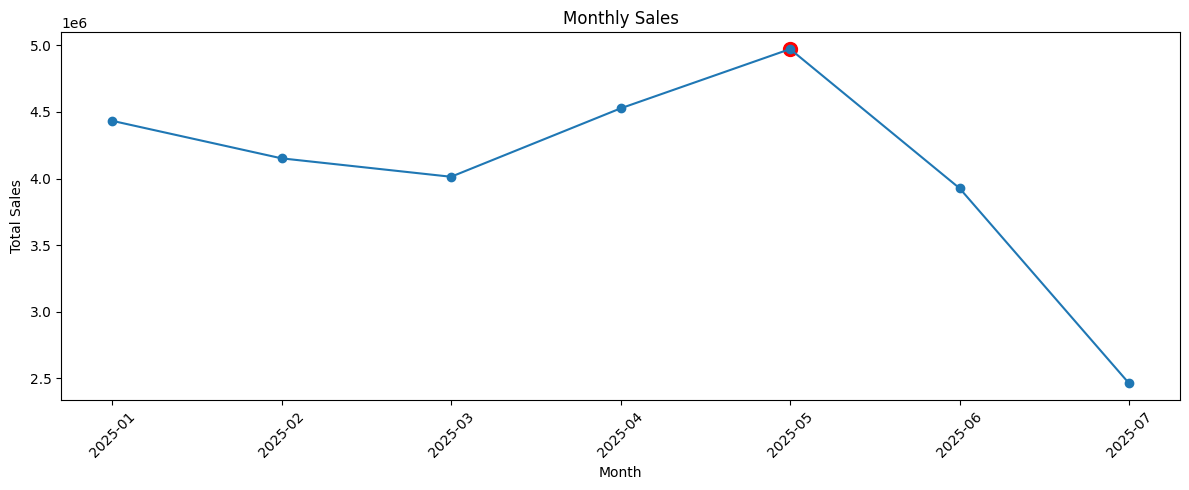

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

# Highlight highest-sales month
plt.scatter(
    str(highest_month),
    highest_sales,
    s=100,
    color='red'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

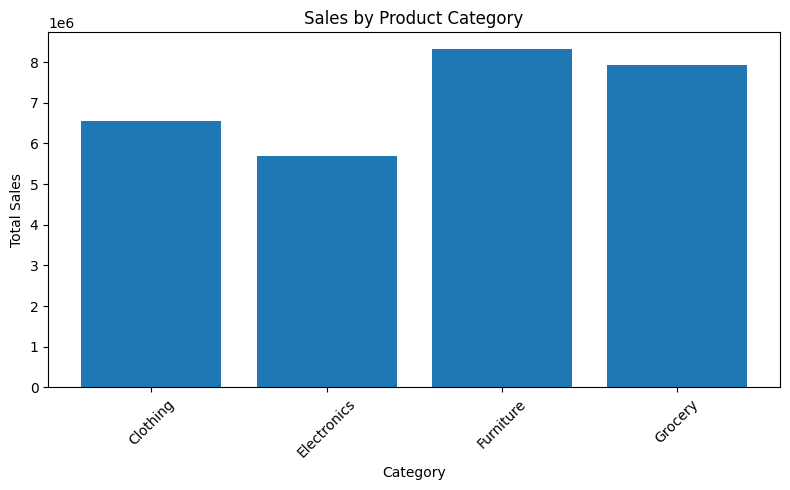

In [14]:
#A. Sales Across Product Categories
category_sales = df.groupby('Category')['Sales'].sum()

plt.figure(figsize=(8, 5))

plt.bar(category_sales.index, category_sales.values)

plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.title('Sales by Product Category')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

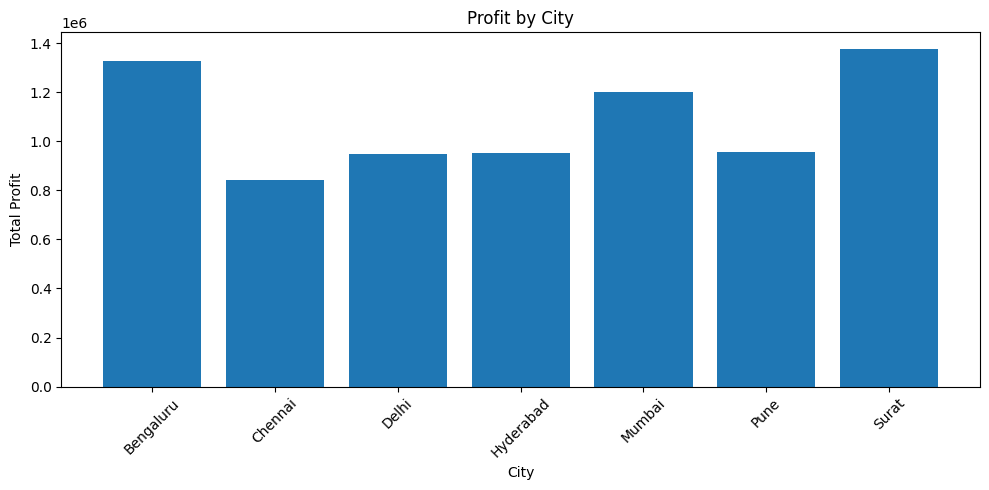

In [15]:
#B. Profit Across Cities
city_profit = df.groupby('City')['Profit'].sum()

plt.figure(figsize=(10, 5))

plt.bar(city_profit.index, city_profit.values)

plt.xlabel('City')
plt.ylabel('Total Profit')
plt.title('Profit by City')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
#Top 5 Products by Sales
product_sales = (
    df.groupby('Product')['Sales']
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

print(product_sales)

Product
Sofa      3127471.60
Snacks    2713070.85
Oil       2678849.65
Bed       2382264.00
Jacket    2368124.65
Name: Sales, dtype: float64


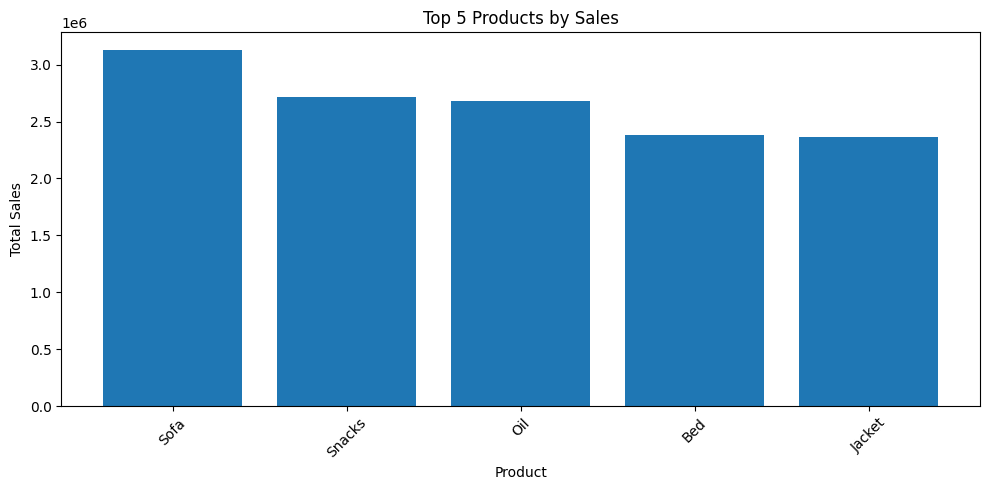

In [ ]:
#the plot
plt.figure(figsize=(10, 5))

plt.bar(product_sales.index, product_sales.values)

plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Top 5 Products by Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

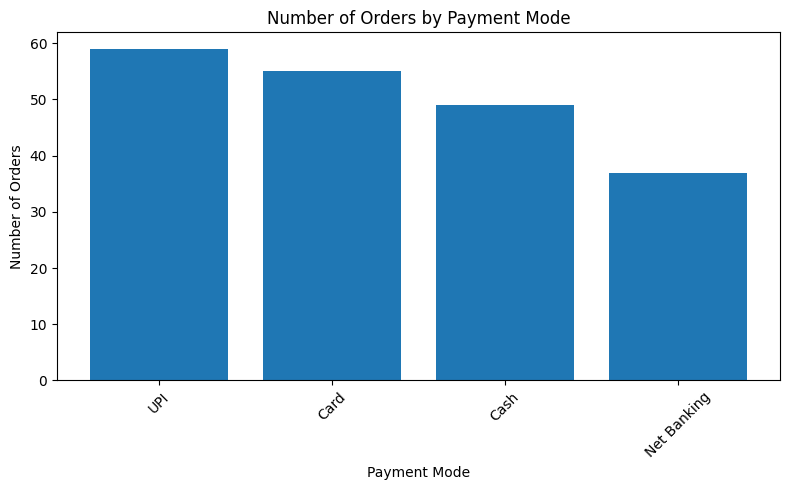

In [18]:
#number of Orders by Payment Mode
payment_orders = df['Payment_Mode'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(payment_orders.index, payment_orders.values)

plt.xlabel('Payment Mode')
plt.ylabel('Number of Orders')
plt.title('Number of Orders by Payment Mode')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


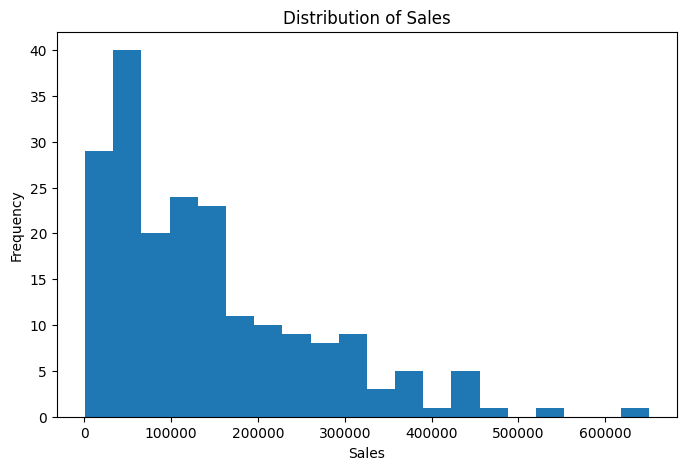

In [19]:
#Sales Distribution
plt.figure(figsize=(8, 5))

plt.hist(df['Sales'], bins=20)

plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Sales')

plt.show()

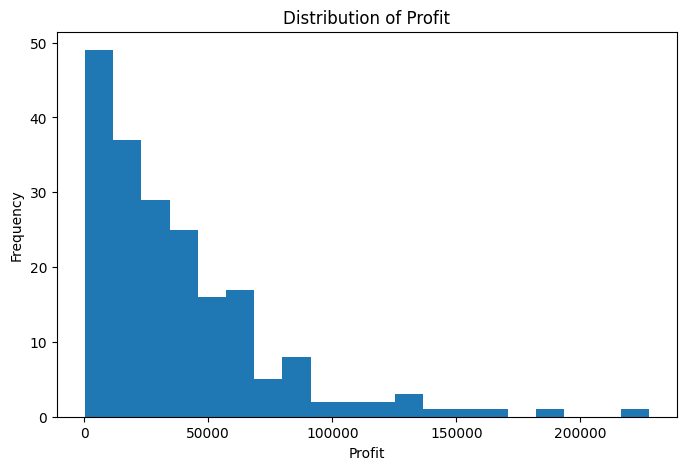

In [20]:
#B. Profit Distribution
plt.figure(figsize=(8, 5))

plt.hist(df['Profit'], bins=20)

plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.title('Distribution of Profit')

plt.show()

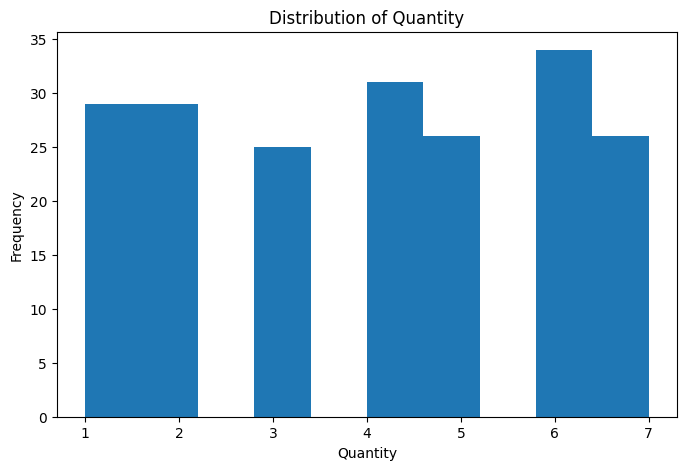

In [21]:
#C. Quantity Distribution
plt.figure(figsize=(8, 5))

plt.hist(df['Quantity'], bins=10)

plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.title('Distribution of Quantity')

plt.show()

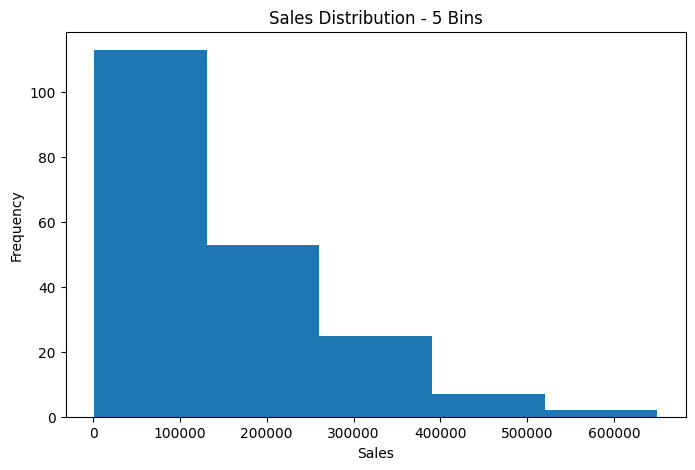

In [22]:
#Change Number of Bins
plt.figure(figsize=(8, 5))

plt.hist(df['Sales'], bins=5)

plt.title('Sales Distribution - 5 Bins')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

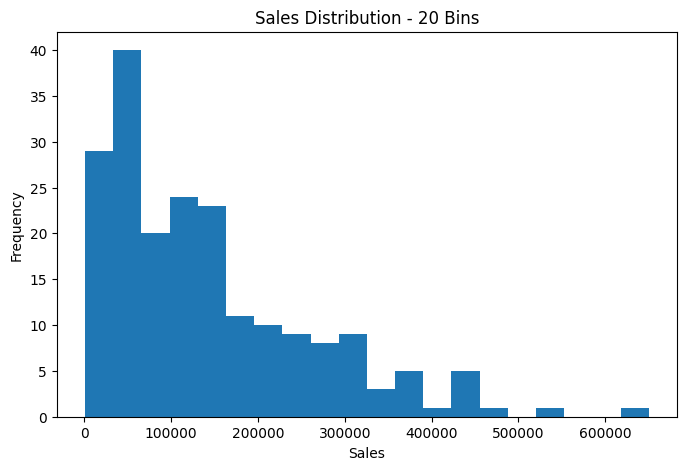

In [23]:
#no bins changed

plt.figure(figsize=(8, 5))

plt.hist(df['Sales'], bins=20)

plt.title('Sales Distribution - 20 Bins')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

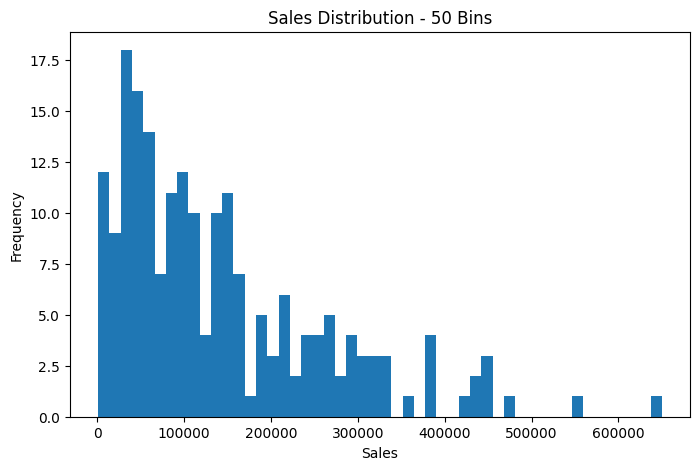

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df['Sales'], bins=50)

plt.title('Sales Distribution - 50 Bins')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.show()

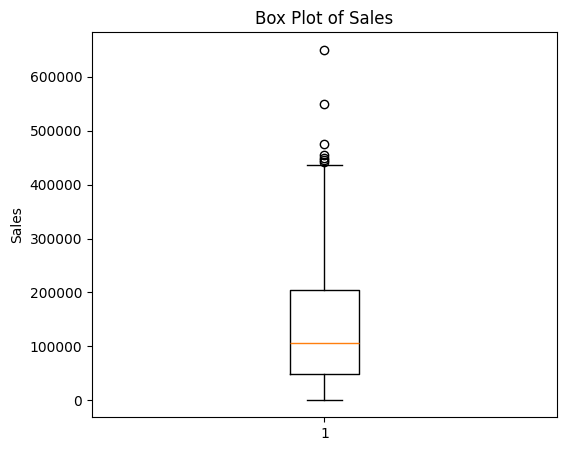

In [25]:
#A. Box Plot for Sales
plt.figure(figsize=(6, 5))

plt.boxplot(df['Sales'].dropna())

plt.ylabel('Sales')
plt.title('Box Plot of Sales')

plt.show()

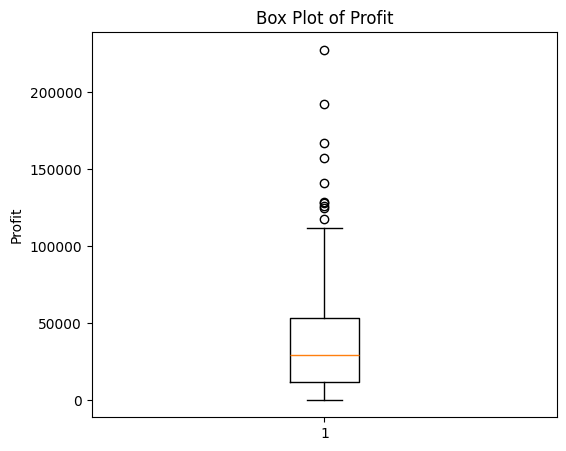

In [26]:
#B. Box Plot for Profit
plt.figure(figsize=(6, 5))

plt.boxplot(df['Profit'].dropna())

plt.ylabel('Profit')
plt.title('Box Plot of Profit')

plt.show()

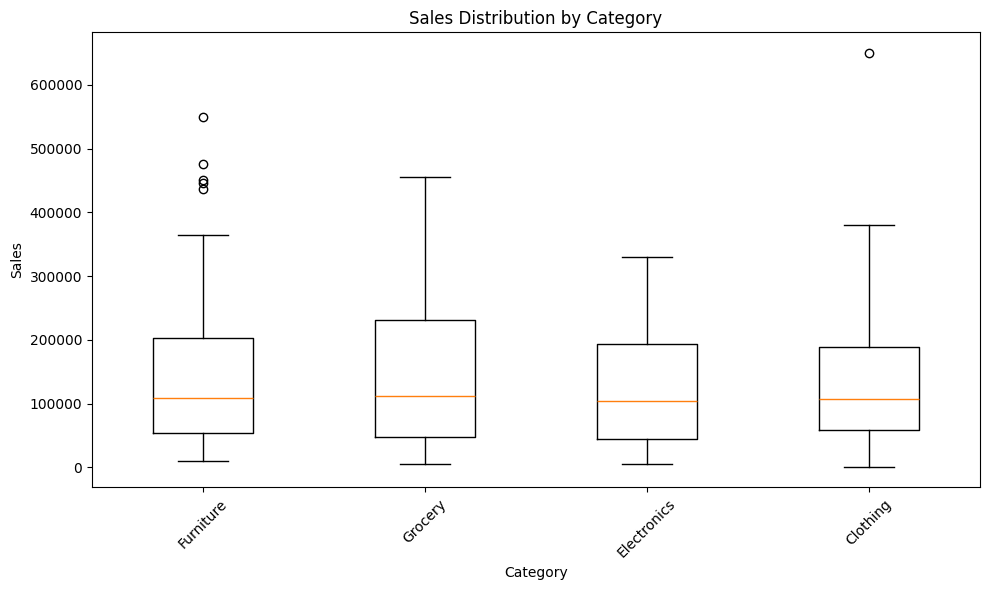

In [27]:
#Sales Grouped by Category
categories = df['Category'].unique()

sales_by_category = [
    df[df['Category'] == category]['Sales'].dropna()
    for category in categories
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    sales_by_category,
    labels=categories
)

plt.xlabel('Category')
plt.ylabel('Sales')
plt.title('Sales Distribution by Category')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
#Identifying Outliers
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Sales'] < lower_bound) |
    (df['Sales'] > upper_bound)
]

print(outliers)

     Order_ID Order_Date     City   Category Product  Quantity  Unit_Price  \
10       1011 2025-01-11  Chennai  Furniture    Sofa         3       29875   
68       1069 2025-03-10    Delhi    Grocery     Oil         6       75853   
75       1076 2025-03-17    Surat   Clothing  Jacket         6       26592   
111      1112 2025-04-22   Mumbai  Furniture    Sofa         7       79959   
138      1139 2025-05-19   Mumbai  Furniture     Bed         7       74960   
144      1145 2025-05-25     Pune    Grocery     Oil         6       77552   
150      1151 2025-05-31     Pune  Furniture     Bed         1       39581   

     Discount      Sales       Cost     Profit Payment_Mode  Rating  \
10         15  450000.00  292500.00  157500.00  Net Banking       3   
68          0  455118.00  393137.11   61980.89         Card       5   
75         15  650000.00  422500.00  227500.00          UPI       2   
111        15  475756.05  426670.07   49085.98          UPI       3   
138        15  44601

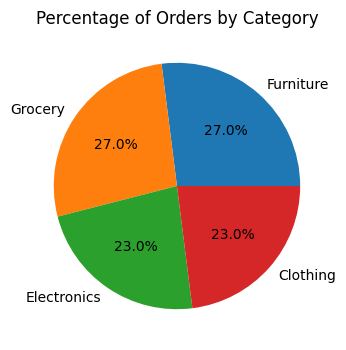

In [31]:
#percentage of orders by category
category_orders = df['Category'].value_counts()

plt.figure(figsize=(4,4))

plt.pie(
    category_orders.values,
    labels=category_orders.index,
    autopct='%1.1f%%'
)

plt.title('Percentage of Orders by Category')

plt.show()

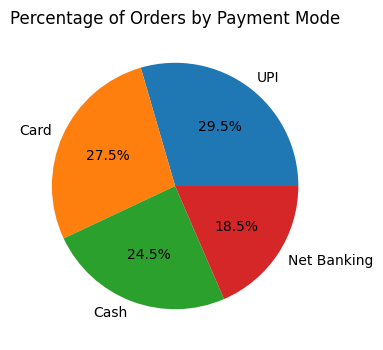

In [32]:
#payment mode
payment_orders = df['Payment_Mode'].value_counts()

plt.figure(figsize=(4,4))

plt.pie(
    payment_orders.values,
    labels=payment_orders.index,
    autopct='%1.1f%%'
)

plt.title('Percentage of Orders by Payment Mode')

plt.show()

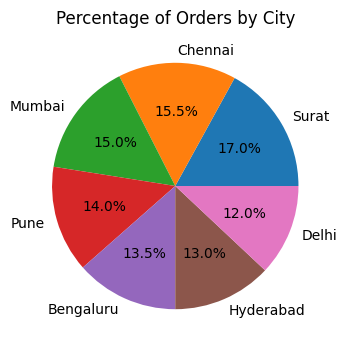

In [34]:
#Percentage of Orders by City
city_orders = df['City'].value_counts()

plt.figure(figsize=(4,4))

plt.pie(
    city_orders.values,
    labels=city_orders.index,
    autopct='%1.1f%%'
)

plt.title('Percentage of Orders by City')

plt.show()

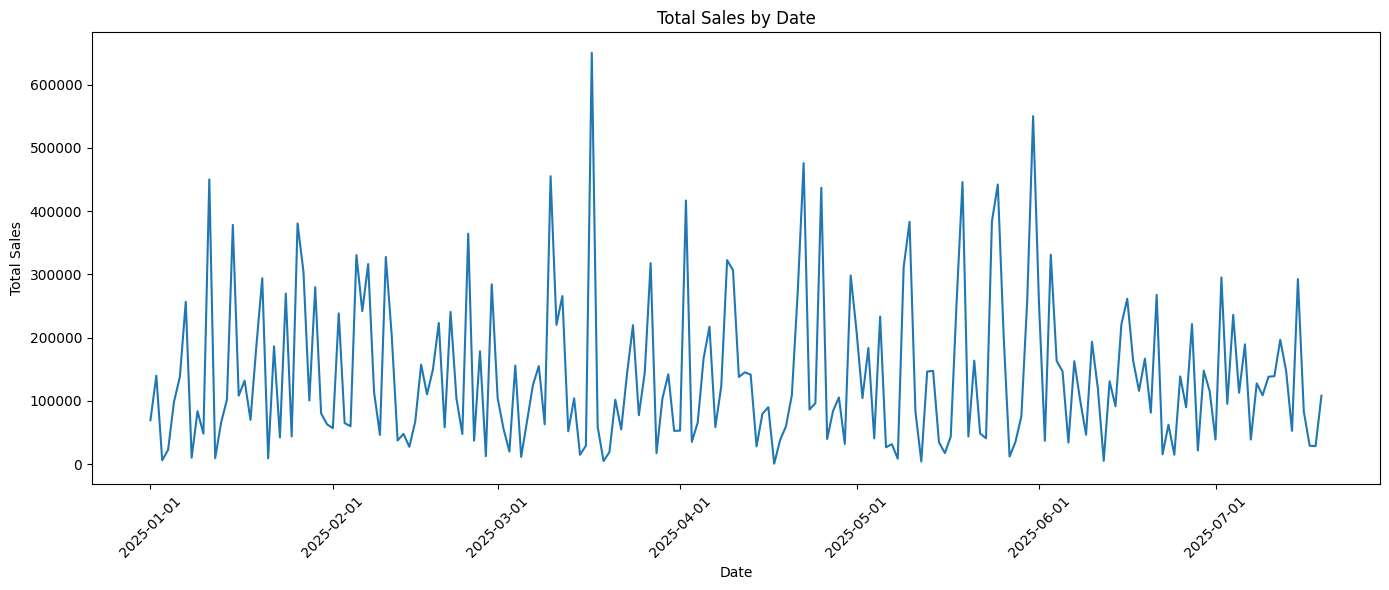

In [36]:

import matplotlib.dates as mdates
# Total sales for each dat
df['Order_Date'] = pd.to_datetime(df['Order_Date'])


daily_sales = df.groupby('Order_Date')['Sales'].sum()

plt.figure(figsize=(14, 6))

plt.plot(daily_sales.index, daily_sales.values)

plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Total Sales by Date')

# Display date as YYYY-MM-DD
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m-%d')
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

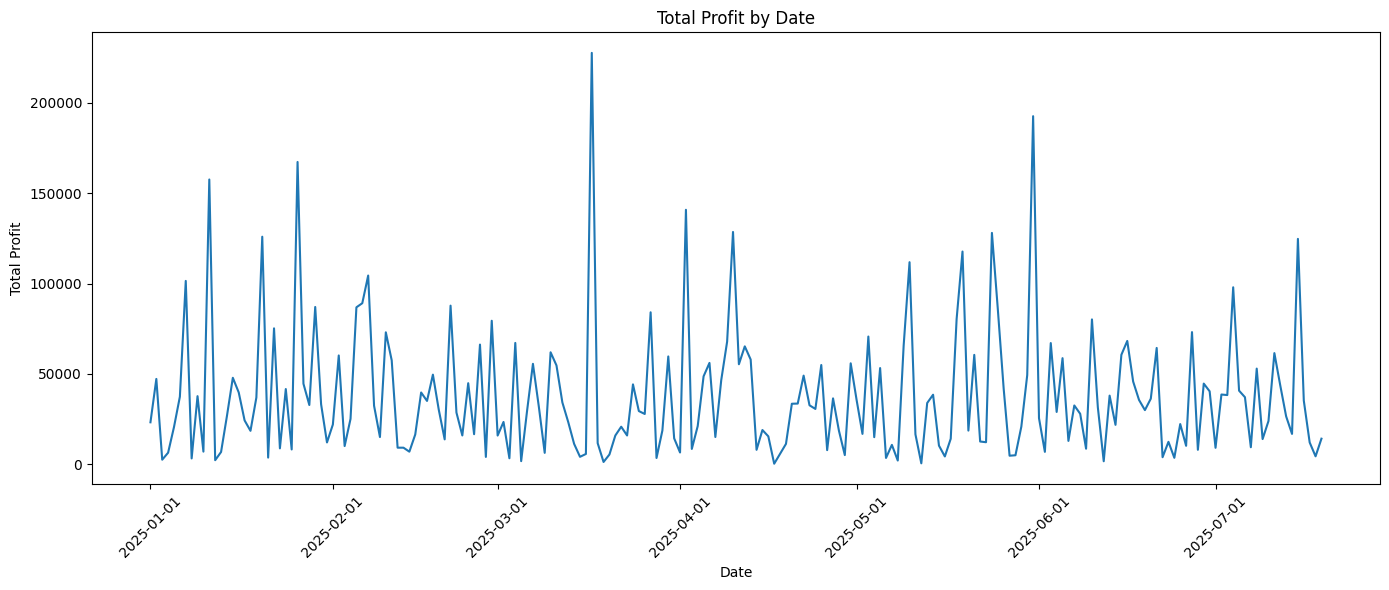

In [37]:
# Total profit for each date
daily_profit = df.groupby('Order_Date')['Profit'].sum()

plt.figure(figsize=(14, 6))

plt.plot(daily_profit.index, daily_profit.values)

plt.xlabel('Date')
plt.ylabel('Total Profit')
plt.title('Total Profit by Date')

# Display date as YYYY-MM-DD
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m-%d')
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

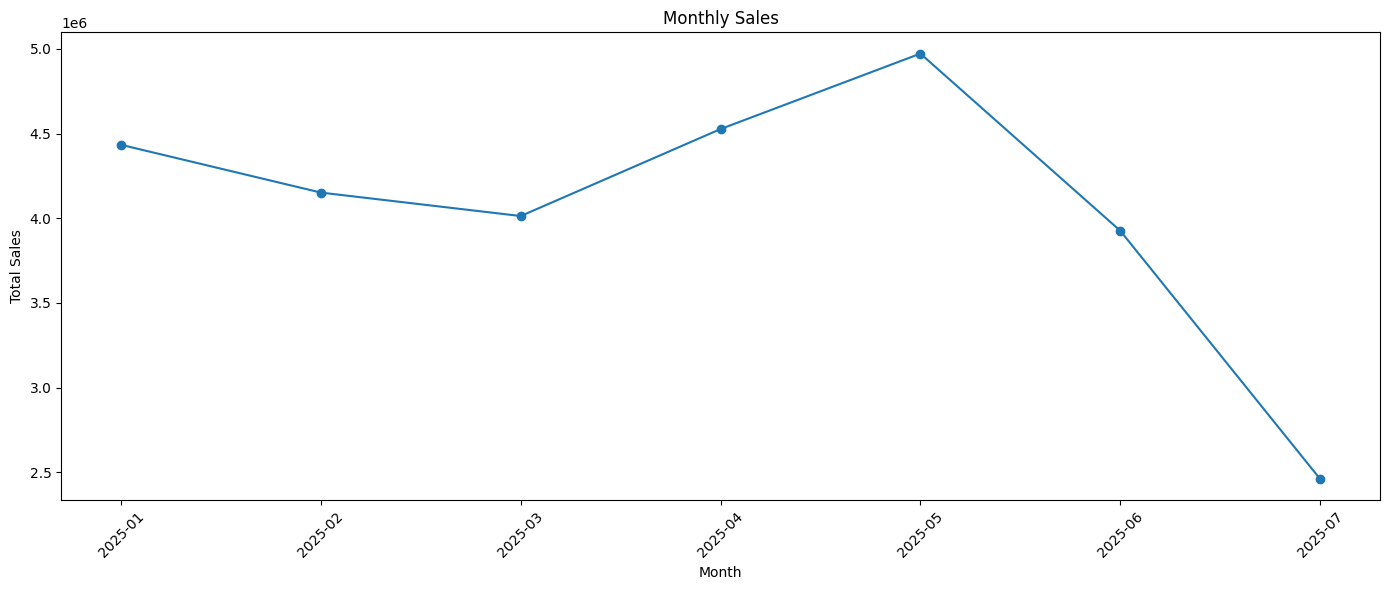

Highest Sales Month: 2025-05
Highest Sales: 4972117.25


In [38]:
# Create Year-Month
df['Year_Month'] = df['Order_Date'].dt.to_period('M')

# Total sales for each month
monthly_sales = df.groupby('Year_Month')['Sales'].sum()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Find highest-sales month
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

print("Highest Sales Month:", highest_month)
print("Highest Sales:", highest_sales)

In [ ]:
#mean sales
mean_sales = df['Sales'].mean()

plt.figure(figsize=(6, 5))

plt.bar(['Sales'], [mean_sales])

plt.xlabel('Metric')
plt.ylabel('Mean Sales')
plt.title('Mean Sales')

plt.show()

print("Mean Sales:", mean_sales)

In [ ]:
#mean profit
mean_profit = df['Profit'].mean()

plt.figure(figsize=(6, 5))

plt.bar(['Profit'], [mean_profit])

plt.xlabel('Metric')
plt.ylabel('Mean Profit')
plt.title('Mean Profit')

plt.show()

print("Mean Profit:", mean_profit)

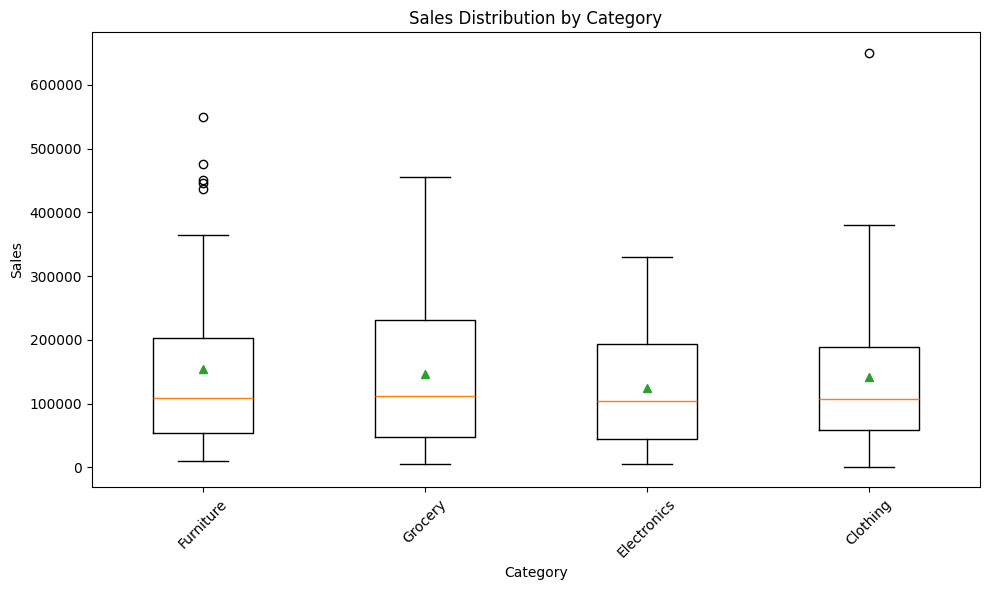

In [42]:
# Sales by Category - Box Plot

categories = df['Category'].unique()

sales_by_category = [
    df[df['Category'] == category]['Sales'].dropna()
    for category in categories
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    sales_by_category,
    labels=categories,
    showmeans=True
)

plt.xlabel('Category')
plt.ylabel('Sales')
plt.title('Sales Distribution by Category')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()